In [1]:
%matplotlib inline

import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

pl.Config.set_float_precision(3)
pl.Config.set_tbl_cols(-1)

RESULTS_BASE = Path(".")
SCHEMES = ["RR-NS", "LL-NS", "LL-SG"]
COMPLETED_EVENTS = ["processed", "violated"]
OUTCOME_EVENTS = ["processed", "violated", "rejected", "dropped"]
DEADLINE = 33.0
BACKEND_LABELS = {0: "RTX 5060", 1: "RTX 4060"}
BACKEND_COLORS = {0: "#1f77b4", 1: "#ff7f0e"}
COLORS = {s: c for s, c in zip(SCHEMES, plt.rcParams["axes.prop_cycle"].by_key()["color"])}

_FILE_RE = re.compile(
    r"^(?P<scheme>[^_]+)_c(?P<nClients>\d+)_b(?P<nBackends>\d+)"
    r"_s(?P<seed>\d+)_r(?P<run>\d+)_(?P<kind>[a-z]+)\.csv$"
)


def _point_root(point: int) -> Path:
    matches = sorted(RESULTS_BASE.glob(f"results_{point:02d}_*"))
    if not matches:
        raise FileNotFoundError(f"No results directory for point {point}")
    return matches[0]


def load_point(point: int, kind: str) -> pl.DataFrame:
    root = _point_root(point)
    dfs = []
    for csv in root.rglob(f"*_{kind}.csv"):
        m = _FILE_RE.match(csv.name)
        if not m:
            continue
        variant = csv.parent.name if csv.parent != root else ""
        df = pl.read_csv(csv).with_columns(
            scheme=pl.lit(m["scheme"]),
            nClients=pl.lit(int(m["nClients"])),
            nBackends=pl.lit(int(m["nBackends"])),
            seed=pl.lit(int(m["seed"])),
            variant=pl.lit(variant),
        )
        dfs.append(df)
    if not dfs:
        return pl.DataFrame()
    return pl.concat(dfs, how="vertical_relaxed")


def summarise(frames: pl.DataFrame, energy: pl.DataFrame, client_counts, schemes=SCHEMES) -> pl.DataFrame:
    completed = frames.filter(pl.col("event").is_in(COMPLETED_EVENTS))
    latency = (
        completed.filter(pl.col("nClients").is_in(client_counts))
        .group_by(["scheme", "nClients"])
        .agg(pl.col("latency_ms").mean().alias("latency_ms"))
    )
    outcomes = (
        frames.filter(pl.col("nClients").is_in(client_counts))
        .group_by(["scheme", "nClients"])
        .agg(
            generated=(pl.col("event") == "sent").sum() + (pl.col("event") == "dropped").sum(),
            missed=(pl.col("event") == "violated").sum() + (pl.col("event") == "dropped").sum(),
        )
        .with_columns(miss_pct=(pl.col("missed") / pl.col("generated") * 100.0))
        .drop("generated", "missed")
    )
    totals = (
        energy.filter(pl.col("nClients").is_in(client_counts))
        .group_by(["scheme", "nClients", "backend_id"])
        .agg(pl.col("total_energy_j").mean().alias("_e"))
        .group_by(["scheme", "nClients"])
        .agg(pl.col("_e").sum().alias("energy_j"))
    )
    return (
        latency.join(outcomes, on=["scheme", "nClients"])
        .join(totals, on=["scheme", "nClients"])
        .filter(pl.col("scheme").is_in(schemes))
        .sort(["nClients", "scheme"])
    )


def plot_latency_boxes(completed, client_counts, schemes=SCHEMES):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    width = 0.7 / len(schemes)
    for i, scheme in enumerate(schemes):
        offset = (i - (len(schemes) - 1) / 2) * width
        data = [
            completed.filter(
                (pl.col("nClients") == nc) & (pl.col("scheme") == scheme)
            )["latency_ms"].to_numpy()
            for nc in client_counts
        ]
        positions = np.arange(len(client_counts)) + offset
        bp = ax.boxplot(
            data, positions=positions, widths=width * 0.85,
            patch_artist=True, showfliers=False, showmeans=True, whis=(5, 95),
            medianprops={"color": "black", "linewidth": 1.1},
            meanprops={"marker": "D", "markerfacecolor": "white",
                       "markeredgecolor": "black", "markersize": 4},
        )
        for box in bp["boxes"]:
            box.set_facecolor(COLORS[scheme])
            box.set_alpha(0.7)
            box.set_edgecolor("black")
        ax.plot([], [], color=COLORS[scheme], linewidth=8, alpha=0.7, label=scheme)
    ax.axhline(DEADLINE, color="red", linestyle="--", linewidth=0.8, alpha=0.5, label="Deadline")
    ax.set_xticks(np.arange(len(client_counts)))
    ax.set_xticklabels(client_counts)
    ax.set_xlabel("Clients")
    ax.set_ylabel("E2E latency (ms)")
    ax.set_title("E2E latency distribution by scheme")
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()


def plot_violins(completed, client_counts, schemes=SCHEMES,
                 quantiles=(0.05, 0.95), show_stats=True, ymax_pct=95):
    latencies = np.concatenate([
        completed.filter((pl.col("nClients") == nc) & (pl.col("scheme") == s))["latency_ms"].to_numpy()
        for nc in client_counts for s in schemes
    ])
    ymax = float(np.percentile(latencies, ymax_pct))
    fig, axes = plt.subplots(1, len(client_counts),
                             figsize=(4 * len(client_counts), 4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, nc in zip(axes, client_counts):
        sub = completed.filter(pl.col("nClients") == nc)
        data = [sub.filter(pl.col("scheme") == s)["latency_ms"].to_numpy() for s in schemes]
        vp = ax.violinplot(
            data,
            showmeans=show_stats, showmedians=show_stats, showextrema=False,
            quantiles=[list(quantiles)] * len(data),
        )
        for body, s in zip(vp["bodies"], schemes):
            body.set_facecolor(COLORS[s])
            body.set_alpha(0.6)
        ax.axhline(DEADLINE, color="red", linestyle="--", linewidth=0.8, alpha=0.5,
                   label="Deadline" if nc == client_counts[0] else None)
        ax.set_xticks(range(1, len(schemes) + 1))
        ax.set_xticklabels(schemes, fontsize=9)
        ax.set_title(f"{nc} clients")
    axes[0].set_ylabel("E2E latency (ms)")
    axes[0].set_ylim(0, ymax)
    axes[0].legend(loc="upper left")
    fig.suptitle("E2E latency distribution by scheme")
    plt.tight_layout()
    plt.show()


def _grouped_stacked(ax, data, client_counts, schemes, categories, cat_colors):
    n = len(schemes)
    width = 0.7 / n
    for i, scheme in enumerate(schemes):
        offset = (i - (n - 1) / 2) * width
        positions = np.arange(len(client_counts)) + offset
        bottom = np.zeros(len(client_counts))
        for cat in categories:
            vals = np.array([
                (data.filter((pl.col("scheme") == scheme) & (pl.col("nClients") == nc))[cat][0]
                 if data.filter((pl.col("scheme") == scheme) & (pl.col("nClients") == nc)).height else 0.0)
                for nc in client_counts
            ])
            ax.bar(positions, vals, width * 0.9, bottom=bottom,
                   color=cat_colors[cat], edgecolor="black", linewidth=0.3,
                   label=cat if i == 0 else None)
            bottom += vals
    ax.set_xticks(np.arange(len(client_counts)))
    ax.set_xticklabels(client_counts)
    ax.set_xlabel(f"Clients (left to right: {', '.join(schemes)})")


def plot_decomposition(completed, client_counts, schemes=SCHEMES):
    means = (
        completed.filter(pl.col("nClients").is_in(client_counts))
        .group_by(["scheme", "nClients"])
        .agg(
            pl.col("compute_ms").mean().alias("compute"),
            pl.col("queue_ms").mean().alias("queue"),
            pl.col("comm_ms").mean().alias("comm"),
        )
    )
    comp_colors = {"compute": "#1f77b4", "queue": "#ff7f0e", "comm": "#2ca02c"}
    fig, ax = plt.subplots(figsize=(8, 4.5))
    _grouped_stacked(ax, means, client_counts, schemes,
                     ["compute", "queue", "comm"], comp_colors)
    ax.axhline(DEADLINE, color="red", linestyle="--", linewidth=0.8, alpha=0.5, label="Deadline")
    ax.set_ylabel("Mean latency (ms)")
    ax.set_title("Mean latency decomposition by scheme")
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()


def plot_energy(energy, client_counts, schemes=SCHEMES):
    agg = (
        energy.filter(pl.col("nClients").is_in(client_counts))
        .group_by(["scheme", "nClients", "backend_id"])
        .agg(pl.col("total_energy_j").mean().alias("energy"))
    )
    backend_ids = sorted(agg["backend_id"].unique().to_list())
    n = len(schemes)
    width = 0.7 / n
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for i, scheme in enumerate(schemes):
        offset = (i - (n - 1) / 2) * width
        positions = np.arange(len(client_counts)) + offset
        bottom = np.zeros(len(client_counts))
        for bid in backend_ids:
            vals = np.array([
                (agg.filter((pl.col("scheme") == scheme) & (pl.col("nClients") == nc)
                            & (pl.col("backend_id") == bid))["energy"][0]
                 if agg.filter((pl.col("scheme") == scheme) & (pl.col("nClients") == nc)
                               & (pl.col("backend_id") == bid)).height else 0.0)
                for nc in client_counts
            ])
            ax.bar(positions, vals, width * 0.9, bottom=bottom,
                   color=BACKEND_COLORS[bid], edgecolor="black", linewidth=0.3,
                   label=BACKEND_LABELS[bid] if i == 0 else None)
            bottom += vals
    ax.set_xticks(np.arange(len(client_counts)))
    ax.set_xticklabels(client_counts)
    ax.set_xlabel(f"Clients (left to right: {', '.join(schemes)})")
    ax.set_ylabel("Mean total energy (J)")
    ax.set_title("Mean total energy per backend")
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()


def plot_tail(frames, client_counts, schemes=SCHEMES):
    steady = (
        frames.filter(pl.col("event") == "processed")
        .filter(pl.col("latency_ms") < 500)
        .filter(pl.col("nClients").is_in(client_counts))
    )
    tail = (
        steady.group_by(["scheme", "nClients"])
        .agg(
            pl.col("latency_ms").quantile(0.95).alias("p95"),
            pl.col("latency_ms").quantile(0.99).alias("p99"),
        )
        .sort(["scheme", "nClients"])
    )
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for ax, pct, key in [(axes[0], 95, "p95"), (axes[1], 99, "p99")]:
        for scheme in schemes:
            sub = tail.filter(pl.col("scheme") == scheme).sort("nClients")
            ax.plot(sub["nClients"], sub[key], "-o", color=COLORS[scheme], label=scheme)
        ax.axhline(DEADLINE, color="red", linestyle="--", linewidth=0.8, alpha=0.5, label="Deadline")
        ax.set_xticks(client_counts)
        ax.set_xlabel("Clients")
        ax.set_title(f"p{pct} latency")
    axes[0].set_ylabel("Latency (ms)")
    axes[0].legend(loc="upper left")
    fig.suptitle("Tail latency vs client count")
    plt.tight_layout()
    plt.show()


def plot_outcomes(frames, client_counts, schemes=SCHEMES):
    per_seed = (
        frames.filter(pl.col("nClients").is_in(client_counts))
        .group_by(["scheme", "nClients", "seed"])
        .agg(
            (pl.col("event") == "processed").sum().alias("Successful"),
            (pl.col("event") == "violated").sum().alias("Late"),
            (pl.col("event") == "dropped").sum().alias("Dropped"),
        )
    )
    avg = (
        per_seed.group_by(["scheme", "nClients"])
        .agg(pl.col("Successful").mean(), pl.col("Late").mean(), pl.col("Dropped").mean())
    )
    cat_colors = {"Successful": "#2ca02c", "Late": "#d62728", "Dropped": "#7f7f7f"}
    fig, ax = plt.subplots(figsize=(8, 4.5))
    _grouped_stacked(ax, avg, client_counts, schemes,
                     ["Successful", "Late", "Dropped"], cat_colors)
    ax.set_ylabel("Mean frames per run")
    ax.set_title("Mean frame outcomes per run")
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()

## Analytical Reference Values

- Backends: RTX 5060 (19.2 TFLOP/s, 32 GB/s transfer BW, 18.3 nF, 9 W static) and RTX 4060 (15.1 TFLOP/s, 4 GB/s, 16.6 nF, 13 W); 7.5 % compute efficiency on both. Hetero = 5060 + 4060, homog = 2x 5060.
- Workload: YOLOv8n, 8.7 GFLOP / 60 KB input / 1 KB output per frame; YOLOv8s for Scenario 3 (28.6 GFLOP). Scenario 4 runs YOLOv8n at 60 fps; other scenarios at 30 fps.
- Network: 802.11ax, 5 GHz, 80 MHz (160 MHz in Scenario 2), disc $r = 5\,\text{m}$.
- Admission: MaxActiveTasksPolicy, threshold 4 per backend.

## 1. YOLOv8n at 30 fps baseline

Hetero cluster under stochastic YOLOv8n at 30 fps, three schemes, $c \in \{1, 2, 4, 8\}$. Establishes the reference latency, miss rate and energy the later scenarios are compared against.

In [2]:
CLIENT_COUNTS = [4, 8]

frames = load_point(1, "frames")
energy = load_point(1, "energy")
completed = frames.filter(pl.col("event").is_in(COMPLETED_EVENTS)) \
                  .filter(pl.col("nClients").is_in(CLIENT_COUNTS))

print(summarise(frames, energy, CLIENT_COUNTS))

shape: (6, 5)
┌────────┬──────────┬────────────┬──────────┬──────────┐
│ scheme ┆ nClients ┆ latency_ms ┆ miss_pct ┆ energy_j │
│ ---    ┆ ---      ┆ ---        ┆ ---      ┆ ---      │
│ str    ┆ i32      ┆ f64        ┆ f64      ┆ f64      │
╞════════╪══════════╪════════════╪══════════╪══════════╡
│ LL-NS  ┆ 4        ┆ 12.340     ┆ 4.329    ┆ 2315.773 │
│ LL-SG  ┆ 4        ┆ 14.274     ┆ 4.503    ┆ 1939.521 │
│ RR-NS  ┆ 4        ┆ 12.475     ┆ 3.649    ┆ 2353.805 │
│ LL-NS  ┆ 8        ┆ 33.988     ┆ 36.239   ┆ 3075.724 │
│ LL-SG  ┆ 8        ┆ 36.287     ┆ 37.012   ┆ 2493.643 │
│ RR-NS  ┆ 8        ┆ 34.321     ┆ 36.764   ┆ 3115.159 │
└────────┴──────────┴────────────┴──────────┴──────────┘


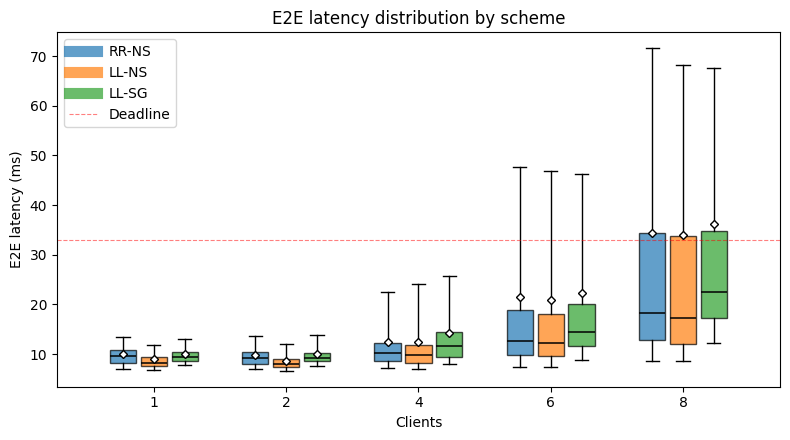

In [3]:
BOX_CLIENTS = [1, 2, 4, 6, 8]
boxes = frames.filter(
    pl.col("event").is_in(COMPLETED_EVENTS)
    & pl.col("nClients").is_in(BOX_CLIENTS)
)
plot_latency_boxes(boxes, BOX_CLIENTS)

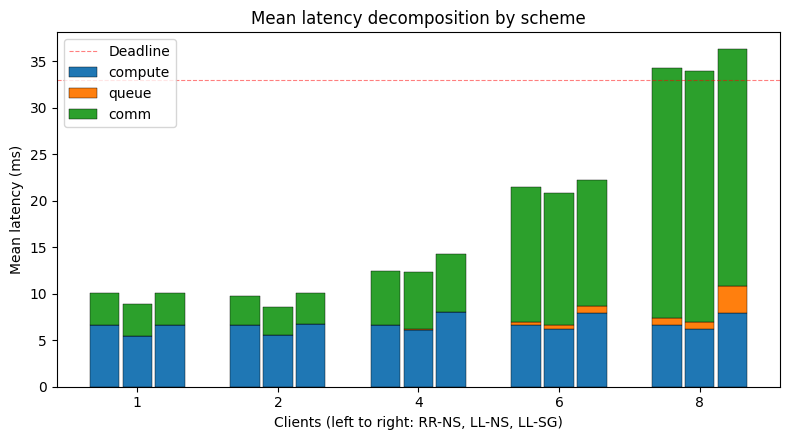

In [4]:
plot_decomposition(frames.filter(pl.col("event").is_in(COMPLETED_EVENTS)), [1, 2, 4, 6, 8])

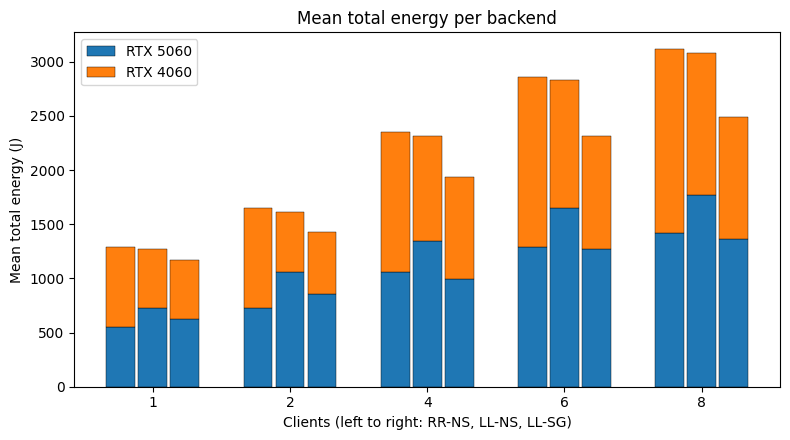

In [5]:
plot_energy(energy, [1, 2, 4, 6, 8])

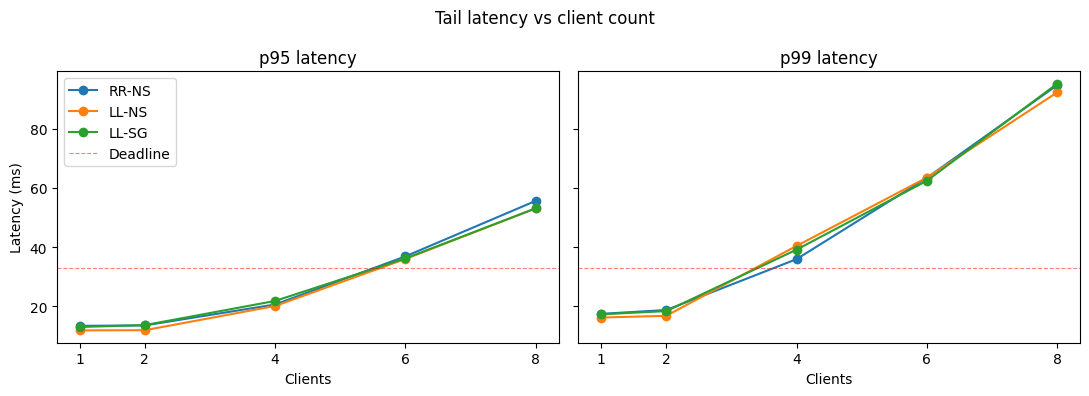

In [6]:
plot_tail(frames, [1, 2, 4, 6, 8])

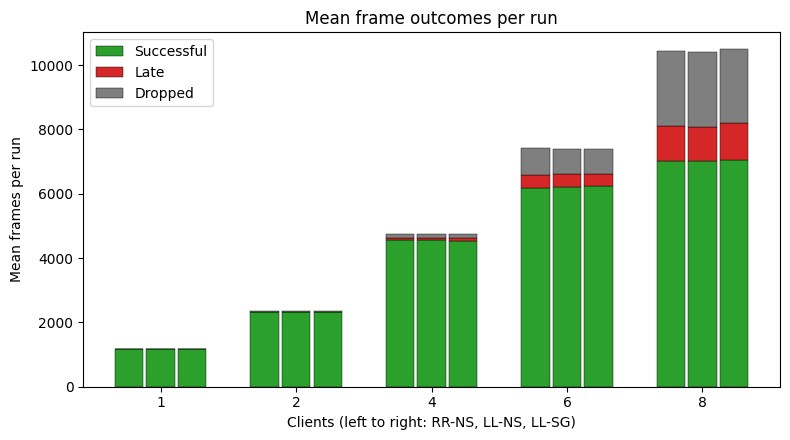

In [7]:
plot_outcomes(frames, [1, 2, 4, 6, 8])

## 2. YOLOv8n at 30 fps, 160 MHz channel

Scenario 1 rerun with the WiFi channel width doubled from 80 MHz to 160 MHz.

In [8]:
def _queue_at_c8(point: int) -> pl.DataFrame:
    return (
        load_point(point, "frames")
        .filter((pl.col("event") == "processed") & (pl.col("nClients") == 8))
        .group_by("scheme")
        .agg(pl.col("queue_ms").mean().alias("queue_ms"))
    )

q80 = _queue_at_c8(1).rename({"queue_ms": "queue_80MHz"})
q160 = _queue_at_c8(2).rename({"queue_ms": "queue_160MHz"})

table = (
    q80.join(q160, on="scheme")
    .with_columns((pl.col("queue_160MHz") - pl.col("queue_80MHz")).alias("delta"))
    .filter(pl.col("scheme").is_in(["LL-NS", "LL-SG"]))
    .sort("scheme")
)
print(table)

shape: (2, 4)
┌────────┬─────────────┬──────────────┬───────┐
│ scheme ┆ queue_80MHz ┆ queue_160MHz ┆ delta │
│ ---    ┆ ---         ┆ ---          ┆ ---   │
│ str    ┆ f64         ┆ f64          ┆ f64   │
╞════════╪═════════════╪══════════════╪═══════╡
│ LL-NS  ┆ 0.818       ┆ 0.937        ┆ 0.119 │
│ LL-SG  ┆ 3.215       ┆ 3.733        ┆ 0.518 │
└────────┴─────────────┴──────────────┴───────┘


In [9]:
CLIENT_COUNTS = [4, 8]

frames = load_point(2, "frames")
energy = load_point(2, "energy")
completed = frames.filter(pl.col("event").is_in(COMPLETED_EVENTS)) \
                  .filter(pl.col("nClients").is_in(CLIENT_COUNTS))

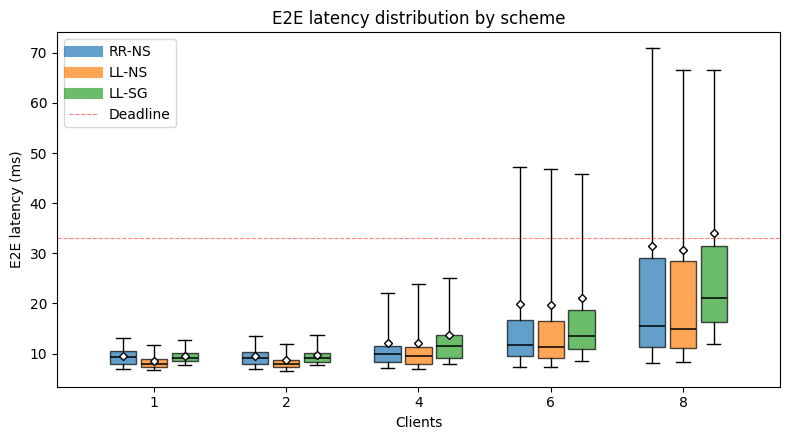

In [10]:
BOX_CLIENTS = [1, 2, 4, 6, 8]
boxes = frames.filter(
    pl.col("event").is_in(COMPLETED_EVENTS)
    & pl.col("nClients").is_in(BOX_CLIENTS)
)
plot_latency_boxes(boxes, BOX_CLIENTS)

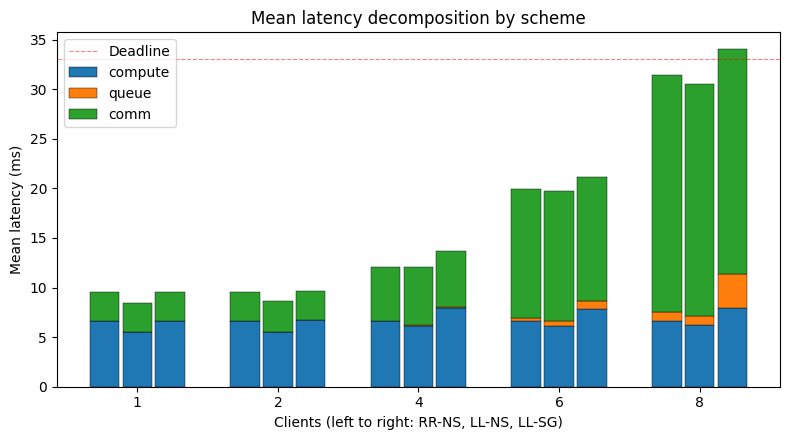

In [11]:
plot_decomposition(frames.filter(pl.col("event").is_in(COMPLETED_EVENTS)), [1, 2, 4, 6, 8])

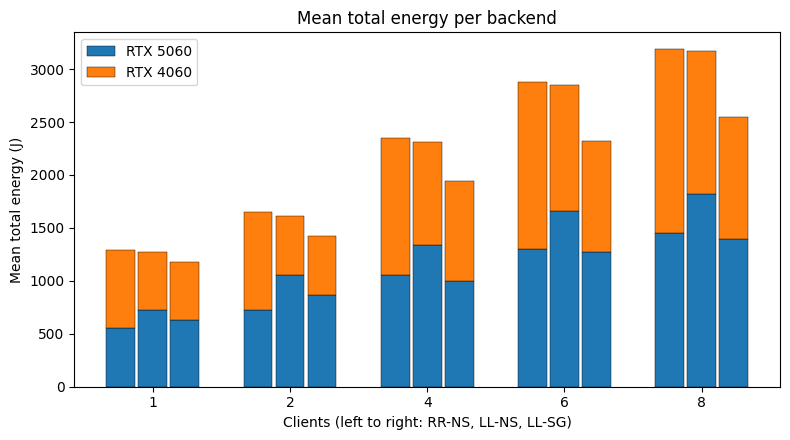

In [12]:
plot_energy(energy, [1, 2, 4, 6, 8])

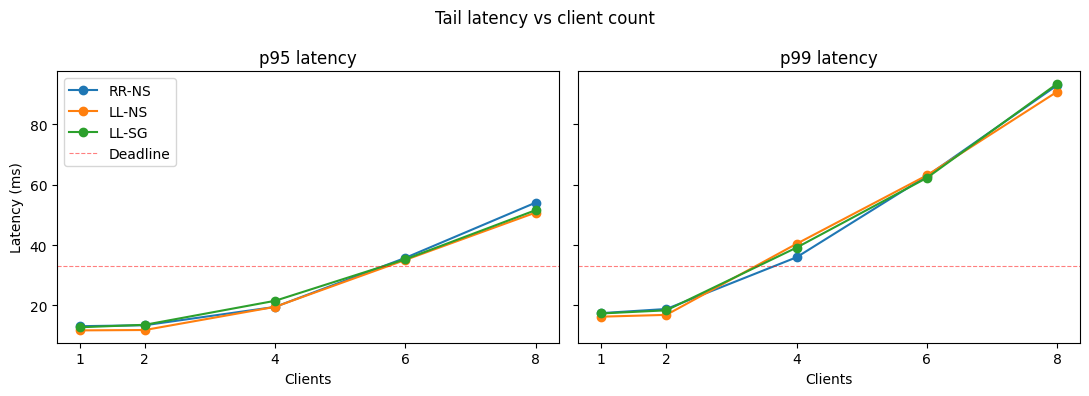

In [13]:
plot_tail(frames, [1, 2, 4, 6, 8])

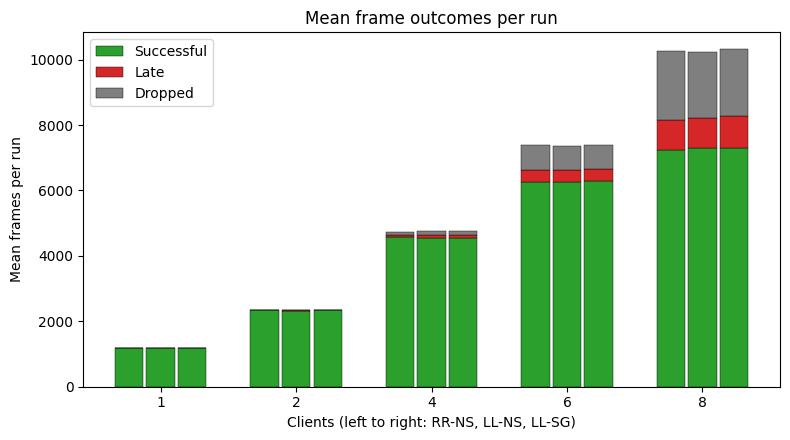

In [14]:
plot_outcomes(frames, [1, 2, 4, 6, 8])

## 3. YOLOv8s at 30 fps

Scenario 1 with YOLOv8s (28.6 GFLOP) in place of YOLOv8n. Pushes per-frame compute above two-thirds of the 33 ms deadline and flips the system into the compute-bound regime.

In [15]:
CLIENT_COUNTS = [1, 2, 4, 8]

frames = load_point(3, "frames")
energy = load_point(3, "energy")
completed = frames.filter(pl.col("event").is_in(COMPLETED_EVENTS)) \
                  .filter(pl.col("nClients").is_in(CLIENT_COUNTS))

outcomes = (
    frames.filter(pl.col("nClients").is_in(CLIENT_COUNTS))
    .group_by(["scheme", "nClients"])
    .agg(
        generated=(pl.col("event") == "sent").sum() + (pl.col("event") == "dropped").sum(),
        missed=(pl.col("event") == "violated").sum() + (pl.col("event") == "dropped").sum(),
    )
    .with_columns(miss_pct=(pl.col("missed") / pl.col("generated") * 100.0))
    .sort(["scheme", "nClients"])
)
print(outcomes)

shape: (12, 5)
┌────────┬──────────┬───────────┬────────┬──────────┐
│ scheme ┆ nClients ┆ generated ┆ missed ┆ miss_pct │
│ ---    ┆ ---      ┆ ---       ┆ ---    ┆ ---      │
│ str    ┆ i32      ┆ u64       ┆ u64    ┆ f64      │
╞════════╪══════════╪═══════════╪════════╪══════════╡
│ LL-NS  ┆ 1        ┆ 11690     ┆ 47     ┆ 0.402    │
│ LL-NS  ┆ 2        ┆ 23380     ┆ 1035   ┆ 4.427    │
│ LL-NS  ┆ 4        ┆ 46751     ┆ 27900  ┆ 59.678   │
│ LL-NS  ┆ 8        ┆ 93338     ┆ 93206  ┆ 99.859   │
│ LL-SG  ┆ 1        ┆ 11690     ┆ 285    ┆ 2.438    │
│ …      ┆ …        ┆ …         ┆ …      ┆ …        │
│ LL-SG  ┆ 8        ┆ 93393     ┆ 93318  ┆ 99.920   │
│ RR-NS  ┆ 1        ┆ 11690     ┆ 778    ┆ 6.655    │
│ RR-NS  ┆ 2        ┆ 23380     ┆ 1249   ┆ 5.342    │
│ RR-NS  ┆ 4        ┆ 46751     ┆ 31979  ┆ 68.403   │
│ RR-NS  ┆ 8        ┆ 93339     ┆ 81149  ┆ 86.940   │
└────────┴──────────┴───────────┴────────┴──────────┘


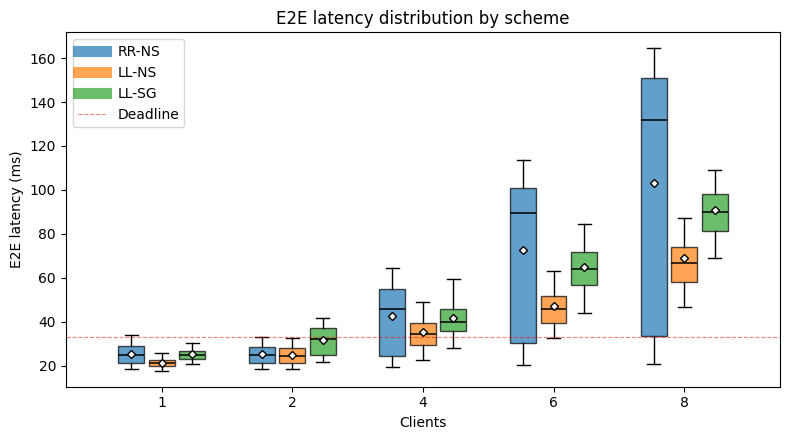

In [16]:
BOX_CLIENTS = [1, 2, 4, 6, 8]
boxes = frames.filter(
    pl.col("event").is_in(COMPLETED_EVENTS)
    & pl.col("nClients").is_in(BOX_CLIENTS)
)
plot_latency_boxes(boxes, BOX_CLIENTS)

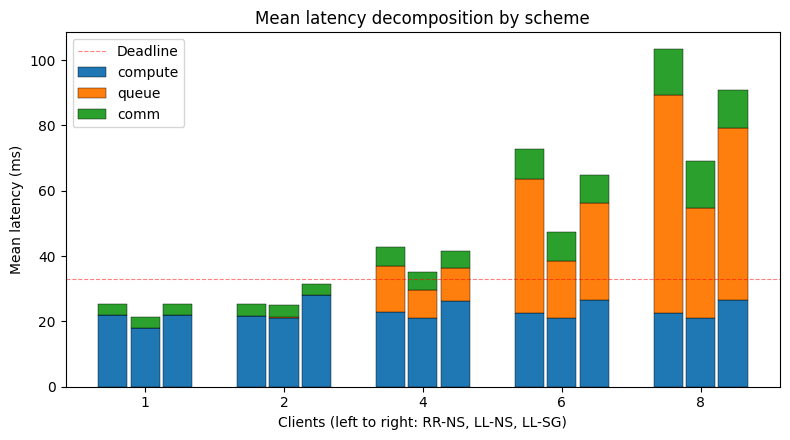

In [17]:
plot_decomposition(frames.filter(pl.col("event").is_in(COMPLETED_EVENTS)), [1, 2, 4, 6, 8])

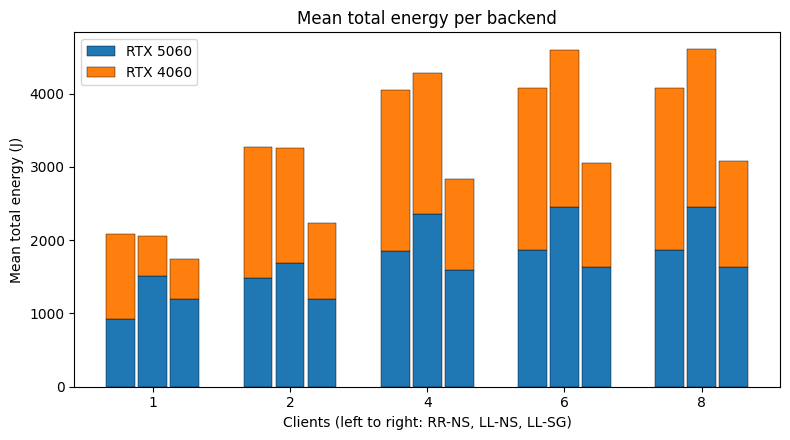

In [18]:
plot_energy(energy, [1, 2, 4, 6, 8])

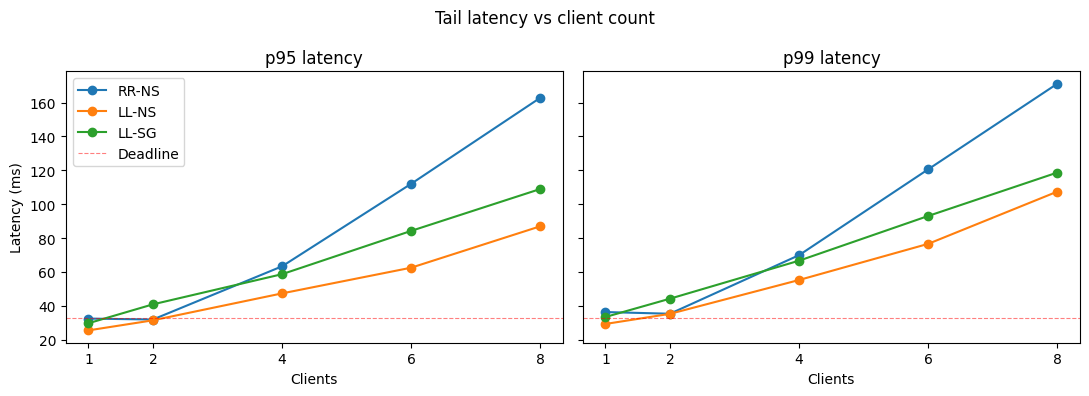

In [19]:
plot_tail(frames, [1, 2, 4, 6, 8])

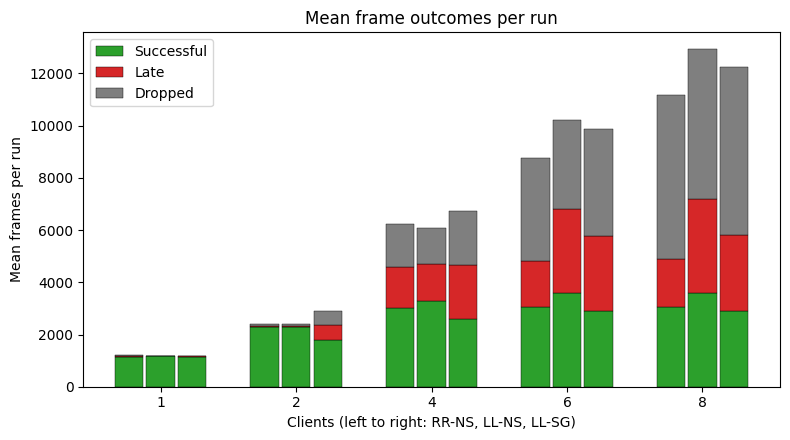

In [20]:
plot_outcomes(frames, [1, 2, 4, 6, 8])

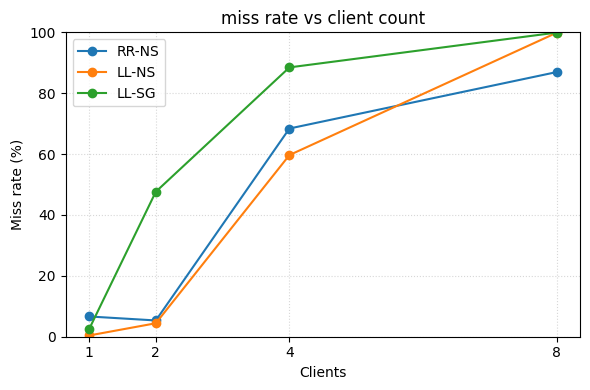

In [21]:
fig, ax = plt.subplots(figsize=(6, 4))
for scheme in SCHEMES:
    sub = outcomes.filter(pl.col("scheme") == scheme).sort("nClients")
    ax.plot(sub["nClients"], sub["miss_pct"], "-o", color=COLORS[scheme], label=scheme)
ax.set_xticks(CLIENT_COUNTS)
ax.set_xlabel("Clients")
ax.set_ylabel("Miss rate (%)")
ax.set_ylim(0, 100)
ax.set_title("miss rate vs client count")
ax.legend(loc="upper left")
ax.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

## 4. YOLOv8n at 60 fps

Scenario 1 rerun at 60 fps instead of 30 fps.

In [22]:
CLIENT_COUNTS = [4, 8]

frames = load_point(4, "frames")
energy = load_point(4, "energy")
completed = frames.filter(pl.col("event").is_in(COMPLETED_EVENTS)) \
                  .filter(pl.col("nClients").is_in(CLIENT_COUNTS))

print(summarise(frames, energy, CLIENT_COUNTS))

shape: (6, 5)
┌────────┬──────────┬────────────┬──────────┬──────────┐
│ scheme ┆ nClients ┆ latency_ms ┆ miss_pct ┆ energy_j │
│ ---    ┆ ---      ┆ ---        ┆ ---      ┆ ---      │
│ str    ┆ i32      ┆ f64        ┆ f64      ┆ f64      │
╞════════╪══════════╪════════════╪══════════╪══════════╡
│ LL-NS  ┆ 4        ┆ 15.610     ┆ 20.596   ┆ 3240.545 │
│ LL-SG  ┆ 4        ┆ 17.304     ┆ 26.747   ┆ 2479.118 │
│ RR-NS  ┆ 4        ┆ 15.902     ┆ 21.944   ┆ 3253.955 │
│ LL-NS  ┆ 8        ┆ 40.571     ┆ 65.436   ┆ 3330.515 │
│ LL-SG  ┆ 8        ┆ 41.261     ┆ 68.800   ┆ 2542.376 │
│ RR-NS  ┆ 8        ┆ 39.805     ┆ 70.134   ┆ 3327.919 │
└────────┴──────────┴────────────┴──────────┴──────────┘


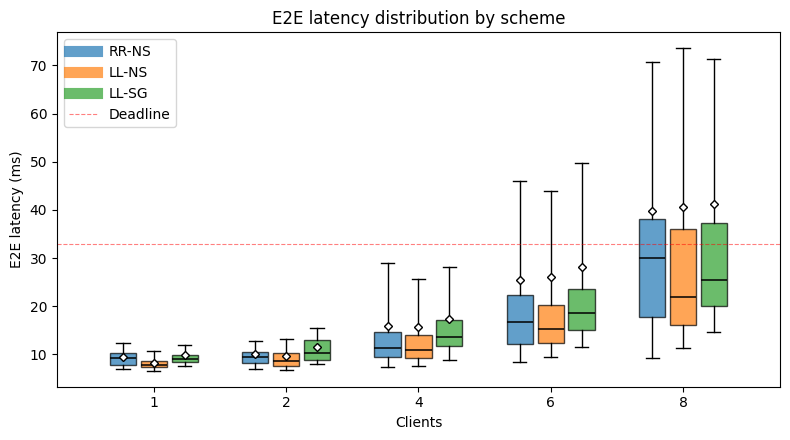

In [23]:
BOX_CLIENTS = [1, 2, 4, 6, 8]
boxes = frames.filter(
    pl.col("event").is_in(COMPLETED_EVENTS)
    & pl.col("nClients").is_in(BOX_CLIENTS)
)
plot_latency_boxes(boxes, BOX_CLIENTS)

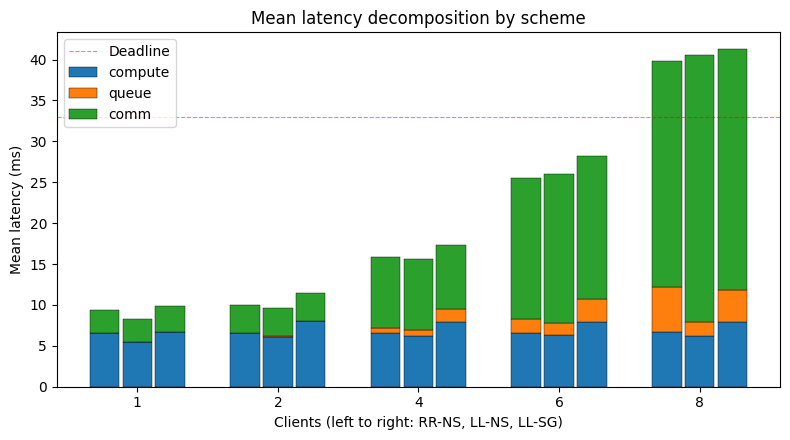

In [24]:
plot_decomposition(frames.filter(pl.col("event").is_in(COMPLETED_EVENTS)), [1, 2, 4, 6, 8])

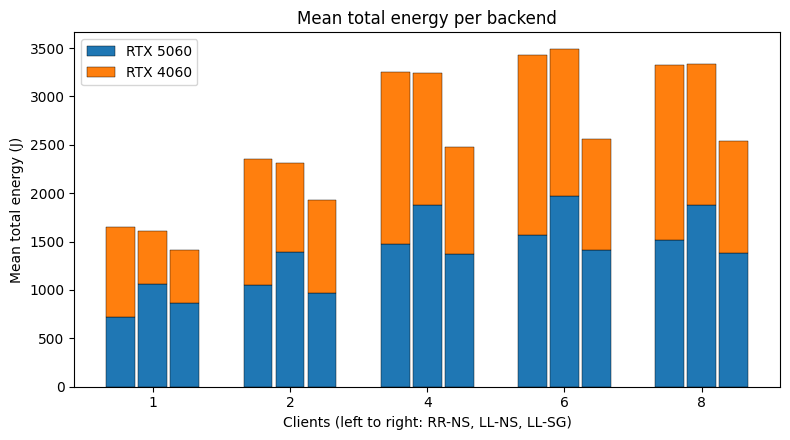

In [25]:
plot_energy(energy, [1, 2, 4, 6, 8])

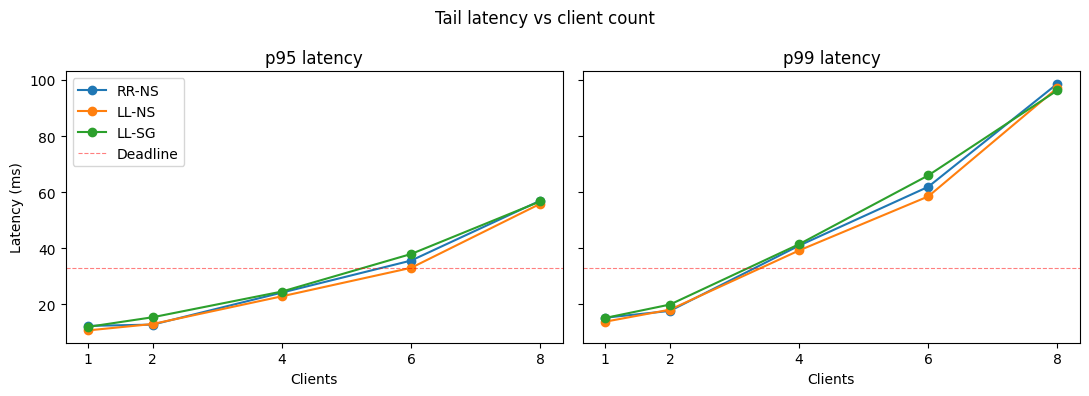

In [26]:
plot_tail(frames, [1, 2, 4, 6, 8])

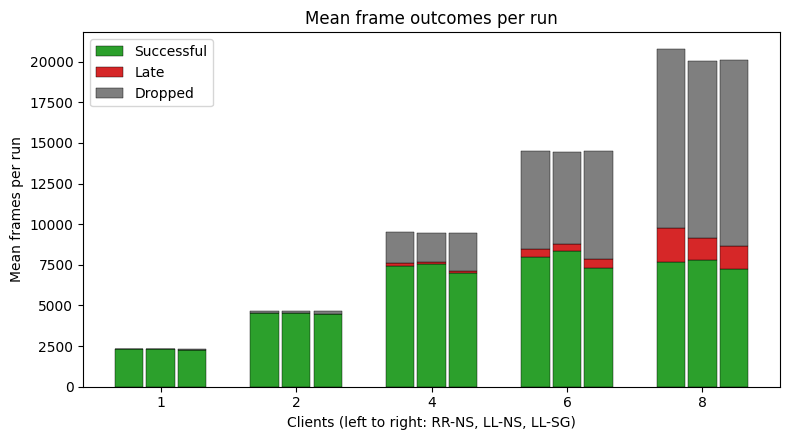

In [27]:
plot_outcomes(frames, [1, 2, 4, 6, 8])

## 5. MU-OFDMA at 30 fps (hetero)

MU-OFDMA (DL + UL OFDMA, BSRP off) on Scenario 1's setup. Tests whether a MAC-layer upgrade effects communication time.

In [28]:
frames_su = (
    load_point(1, "frames")
    .filter(pl.col("scheme") == "LL-NS")
    .filter(pl.col("event").is_in(COMPLETED_EVENTS))
)
frames_mu = (
    load_point(5, "frames")
    .filter(pl.col("event").is_in(COMPLETED_EVENTS))
)


def _decompose(df, label):
    return (
        df.group_by("nClients")
        .agg(
            pl.col("compute_ms").mean().alias("compute"),
            pl.col("queue_ms").mean().alias("queue"),
            pl.col("comm_ms").mean().alias("comm"),
            pl.col("latency_ms").mean().alias("latency"),
        )
        .with_columns(mac=pl.lit(label))
        .sort("nClients")
    )


combined = pl.concat([_decompose(frames_su, "SU"), _decompose(frames_mu, "MU-OFDMA")])
CLIENT_COUNTS = sorted(
    set(combined.filter(pl.col("mac") == "SU")["nClients"].to_list())
    & set(combined.filter(pl.col("mac") == "MU-OFDMA")["nClients"].to_list())
)
combined = combined.filter(pl.col("nClients").is_in(CLIENT_COUNTS))
print(combined.sort(["nClients", "mac"]))

shape: (10, 6)
┌──────────┬─────────┬───────┬────────┬─────────┬──────────┐
│ nClients ┆ compute ┆ queue ┆ comm   ┆ latency ┆ mac      │
│ ---      ┆ ---     ┆ ---   ┆ ---    ┆ ---     ┆ ---      │
│ i32      ┆ f64     ┆ f64   ┆ f64    ┆ f64     ┆ str      │
╞══════════╪═════════╪═══════╪════════╪═════════╪══════════╡
│ 1        ┆ 5.485   ┆ 0.000 ┆ 3.786  ┆ 9.271   ┆ MU-OFDMA │
│ 1        ┆ 5.485   ┆ 0.000 ┆ 3.434  ┆ 8.919   ┆ SU       │
│ 2        ┆ 5.512   ┆ 0.003 ┆ 3.788  ┆ 9.303   ┆ MU-OFDMA │
│ 2        ┆ 5.516   ┆ 0.004 ┆ 3.078  ┆ 8.598   ┆ SU       │
│ 4        ┆ 6.084   ┆ 0.106 ┆ 9.869  ┆ 16.058  ┆ MU-OFDMA │
│ 4        ┆ 6.114   ┆ 0.110 ┆ 6.116  ┆ 12.340  ┆ SU       │
│ 6        ┆ 6.132   ┆ 0.317 ┆ 21.380 ┆ 27.829  ┆ MU-OFDMA │
│ 6        ┆ 6.160   ┆ 0.489 ┆ 14.159 ┆ 20.807  ┆ SU       │
│ 8        ┆ 6.142   ┆ 0.527 ┆ 47.571 ┆ 54.240  ┆ MU-OFDMA │
│ 8        ┆ 6.207   ┆ 0.792 ┆ 26.989 ┆ 33.988  ┆ SU       │
└──────────┴─────────┴───────┴────────┴─────────┴──────────┘


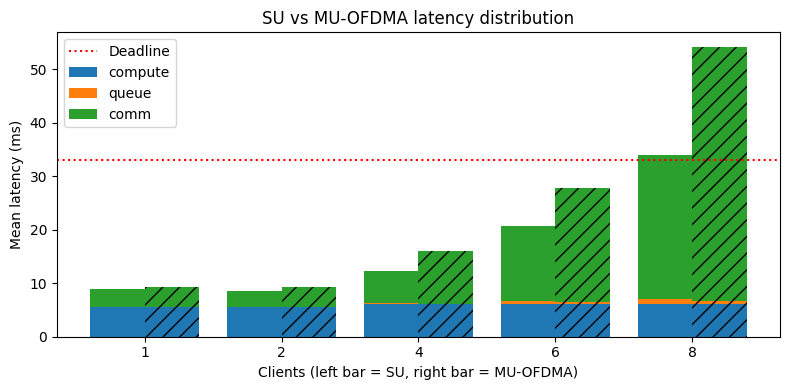

In [29]:
LABELS = ["SU", "MU-OFDMA"]
width = 0.4

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(CLIENT_COUNTS))
for i, label in enumerate(LABELS):
    sub = combined.filter(pl.col("mac") == label).sort("nClients")
    compute = sub["compute"].to_numpy()
    queue = sub["queue"].to_numpy()
    comm = sub["comm"].to_numpy()
    offset = (i - 0.5) * width
    hatch = "" if i == 0 else "//"
    ax.bar(x + offset, compute, width, color="#1f77b4", hatch=hatch,
           label="compute" if i == 0 else None)
    ax.bar(x + offset, queue, width, bottom=compute, color="#ff7f0e", hatch=hatch,
           label="queue" if i == 0 else None)
    ax.bar(x + offset, comm, width, bottom=compute + queue, color="#2ca02c", hatch=hatch,
           label="comm" if i == 0 else None)
ax.axhline(DEADLINE, color="red", linestyle=":", label="Deadline")
ax.set_xticks(x)
ax.set_xticklabels(CLIENT_COUNTS)
ax.set_xlabel("Clients (left bar = SU, right bar = MU-OFDMA)")
ax.set_ylabel("Mean latency (ms)")
ax.set_title("SU vs MU-OFDMA latency distribution")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 6. BSRP at low load (30 fps)

MU-OFDMA at 30 fps, with BSRP off vs on. Restricted to low load because BSRP-on trips the ns-3 PHY-state assertion at $c \geq 4$.

In [30]:
raw = load_point(6, "frames").filter(pl.col("event").is_in(COMPLETED_EVENTS))
data = raw.with_columns(bsrp=pl.col("variant").str.split("_").list.last())

combined = (
    data.group_by(["bsrp", "nClients"])
    .agg(
        pl.col("compute_ms").mean().alias("compute"),
        pl.col("queue_ms").mean().alias("queue"),
        pl.col("comm_ms").mean().alias("comm"),
        pl.col("latency_ms").mean().alias("latency"),
    )
    .sort(["nClients", "bsrp"])
)
CLIENT_COUNTS = sorted(combined["nClients"].unique().to_list())
print(combined)

shape: (4, 6)
┌──────┬──────────┬─────────┬───────┬───────┬─────────┐
│ bsrp ┆ nClients ┆ compute ┆ queue ┆ comm  ┆ latency │
│ ---  ┆ ---      ┆ ---     ┆ ---   ┆ ---   ┆ ---     │
│ str  ┆ i32      ┆ f64     ┆ f64   ┆ f64   ┆ f64     │
╞══════╪══════════╪═════════╪═══════╪═══════╪═════════╡
│ off  ┆ 1        ┆ 5.485   ┆ 0.000 ┆ 3.786 ┆ 9.271   │
│ on   ┆ 1        ┆ 5.485   ┆ 0.000 ┆ 3.751 ┆ 9.236   │
│ off  ┆ 2        ┆ 5.512   ┆ 0.003 ┆ 3.788 ┆ 9.303   │
│ on   ┆ 2        ┆ 5.499   ┆ 0.001 ┆ 3.550 ┆ 9.049   │
└──────┴──────────┴─────────┴───────┴───────┴─────────┘


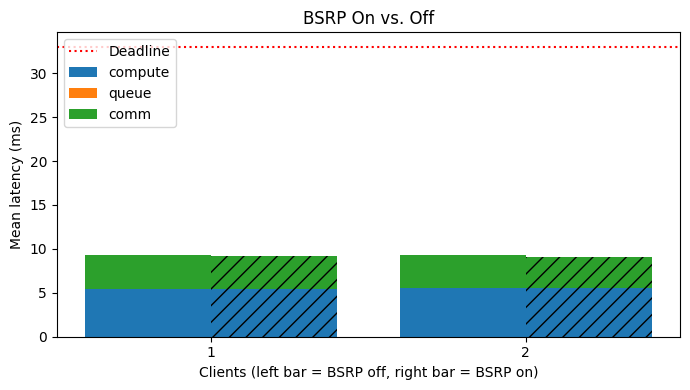

In [31]:
LABELS = ["off", "on"]
width = 0.4

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(CLIENT_COUNTS))
for i, label in enumerate(LABELS):
    sub = combined.filter(pl.col("bsrp") == label).sort("nClients")
    compute = sub["compute"].to_numpy()
    queue = sub["queue"].to_numpy()
    comm = sub["comm"].to_numpy()
    offset = (i - 0.5) * width
    hatch = "" if i == 0 else "//"
    ax.bar(x + offset, compute, width, color="#1f77b4", hatch=hatch,
           label="compute" if i == 0 else None)
    ax.bar(x + offset, queue, width, bottom=compute, color="#ff7f0e", hatch=hatch,
           label="queue" if i == 0 else None)
    ax.bar(x + offset, comm, width, bottom=compute + queue, color="#2ca02c", hatch=hatch,
           label="comm" if i == 0 else None)
ax.axhline(DEADLINE, color="red", linestyle=":", label="Deadline")
ax.set_xticks(x)
ax.set_xticklabels(CLIENT_COUNTS)
ax.set_xlabel("Clients (left bar = BSRP off, right bar = BSRP on)")
ax.set_ylabel("Mean latency (ms)")
ax.set_title("BSRP On vs. Off")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()